# TotalEnergies and the price of oil

## Main question

To what extent do TotalEnergies' results depend on the Brent price, and how much do they fall when oil prices drop?

## Sub-questions

1. **Do the results follow the Brent price?**
   How did adjusted net income, sales and production evolve between 2011 and 2025, compared with the average Brent price? How strongly are these indicators correlated with Brent?
2. **How much is a higher oil price worth?**
   On average, how much does adjusted net income change when Brent changes by 10 USD/bbl? How does this estimate compare with the official sensitivity published by TotalEnergies?
3. **What does the company lose when oil prices fall?**
   During the three downturns of the period (2014-2016, 2020 and after 2022), how far did results fall from their peak? Did they fall faster or slower than the Brent price?
4. **Does the downstream business cushion falling oil prices?**
   How do upstream and downstream (refining, chemicals, marketing) results react to changes in Brent? Does downstream offset part of the upstream losses when prices fall?
5. **Why do net income and adjusted net income diverge in some years?**
   Which years show the largest gaps, and what explains them?

## Data

All data come from TotalEnergies' annual Factbooks (2014 to 2025 editions) and, for a few figures, from its quarterly press releases and SEC filings. Column definitions, sources and checks are detailed in the README.

| File | Content |
| --- | --- |
| `totalenergies_annual_2011_2025.csv` | One row per year: Brent, sales, net income, adjusted net income, production |
| `segments_annual_2011_2025.csv` | Adjusted net operating income by year and by segment |
| `totalenergies_quarterly_2011_2025.csv` | One row per quarter: Brent, liquids price, net income, adjusted net income |
| `segments_quarterly_2011_2025.csv` | Adjusted net operating income by quarter and by segment |

Amounts are in millions of US dollars, Brent in dollars per barrel.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 20)

In [2]:
annual = pd.read_csv("../data/totalenergies_annual_2011_2025.csv")
segments = pd.read_csv("../data/segments_annual_2011_2025.csv")
quarterly = pd.read_csv("../data/totalenergies_quarterly_2011_2025.csv")
segments_q = pd.read_csv("../data/segments_quarterly_2011_2025.csv")

for name, df in [("annual", annual), ("segments", segments), ("quarterly", quarterly), ("segments_q", segments_q)]:
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

annual: 15 rows, 6 columns
segments: 61 rows, 6 columns
quarterly: 60 rows, 6 columns
segments_q: 236 rows, 6 columns


To give all charts the same style, I use a small formatting function. It adds the title, the axis labels, a light grid and the source.

In [3]:
sns.set_theme(style="white")
plt.rcParams["figure.figsize"] = (10, 4.5)

BLUE, ORANGE, GREEN, GREY = "#4C72B0", "#DD8452", "#55A868", "#8C8C8C"


def format_axes(ax: plt.Axes, title: str, xlabel: str, ylabel: str,
                source: str | None = "Source: TotalEnergies Factbooks") -> None:
    """Apply the same style to every chart in the notebook.

    Set source to None for all but one chart of a figure, so the source appears only once.
    """
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    if source:
        ax.figure.text(0.01, -0.03, source, fontsize=8, color="gray")

## 1. Exploring and preparing the data

### 1.1 Structure of the files

In [4]:
display(annual.head())
display(segments_q.head())

,year,brent_avg_usd_per_bbl,sales_musd,net_income_musd,adjusted_net_income_musd,production_kboe_per_day
0,2011,111.3,257084,17400,15948,2346
1,2012,111.7,257037,13648,15772,2300
2,2013,108.7,251725,11228,14292,2299
3,2014,99.0,236122,4244,12837,2146
4,2015,52.4,165357,5087,10518,2347


,quarter,quarter_end_date,segment,group,adjusted_net_operating_income_musd,source
0,2011Q1,2011-03-31,Upstream,Upstream & Gas,NaN,not available
1,2011Q1,2011-03-31,Refining & Chemicals,Downstream,NaN,not available
2,2011Q1,2011-03-31,Marketing & Services,Downstream,NaN,not available
3,2011Q2,2011-06-30,Upstream,Upstream & Gas,NaN,not available
4,2011Q2,2011-06-30,Refining & Chemicals,Downstream,NaN,not available


In [5]:
for name, df in [("annual", annual), ("segments", segments), ("quarterly", quarterly), ("segments_q", segments_q)]:
    print(f"--- {name} ---")
    print(df.dtypes, "\n")

--- annual ---
year                          int64
brent_avg_usd_per_bbl       float64
sales_musd                    int64
net_income_musd               int64
adjusted_net_income_musd      int64
production_kboe_per_day       int64
dtype: object 

--- segments ---
year                                  int64
segment                                 str
group                                   str
adjusted_net_operating_income_musd    int64
factbook_edition                      int64
sheet                                   str
dtype: object 

--- quarterly ---
quarter                              str
quarter_end_date                     str
brent_avg_usd_per_bbl            float64
avg_liquids_price_usd_per_bbl    float64
net_income_musd                  float64
adjusted_net_income_musd         float64
dtype: object 

--- segments_q ---
quarter                                   str
quarter_end_date                          str
segment                                   str
group              

In [6]:
print(segments["group"].value_counts(), "\n")
print(segments["segment"].value_counts())

group
Upstream & Gas    31
Downstream        30
Name: count, dtype: int64 

segment
Refining & Chemicals                  15
Marketing & Services                  15
Exploration & Production              13
Integrated LNG                         5
Integrated Power                       5
Integrated Gas, Renewables & Power     4
Upstream                               2
Gas, Renewables & Power                2
Name: count, dtype: int64


The segment names change over time because TotalEnergies reorganized its business segments several times. The `group` column (Upstream & Gas / Downstream) is the one to use to compare years.

### 1.2 Dates

In the quarterly files, `quarter_end_date` is read as text. I convert it to a date and extract the year, which I will need to group quarters by year.

In [7]:
for df in [quarterly, segments_q]:
    df["quarter_end_date"] = pd.to_datetime(df["quarter_end_date"])
    df["year"] = df["quarter_end_date"].dt.year

quarterly.dtypes

quarter                                     str
quarter_end_date                 datetime64[us]
brent_avg_usd_per_bbl                   float64
avg_liquids_price_usd_per_bbl           float64
net_income_musd                         float64
adjusted_net_income_musd                float64
year                                      int32
dtype: object

### 1.3 Missing values

In [8]:
for name, df in [("annual", annual), ("segments", segments), ("quarterly", quarterly), ("segments_q", segments_q)]:
    print(f"{name}: {df.isna().sum().sum()} missing values")

annual: 0 missing values
segments: 0 missing values
quarterly: 0 missing values
segments_q: 24 missing values


In [9]:
missing = segments_q[segments_q["adjusted_net_operating_income_musd"].isna()]
missing.groupby(["year", "segment"]).size().unstack()

segment,Marketing & Services,Refining & Chemicals,Upstream
year,,,
2011,4,4,4
2012,4,4,4


Only `segments_q` has missing values: the results by segment for every quarter of 2011 and 2012 (24 rows).

**Decision: I keep them.** They only concern the quarterly split by segment in 2011 and 2012, which is outside the three downturns studied, and the annual file covers these years by segment. Filling them would mean inventing data, and pandas already ignores missing values in calculations. The one exception is the quarterly pivot table in section 5.3, where I drop them first: otherwise, `sum` would turn the empty quarters into zeros.

### 1.4 More readable units

Results are in millions of US dollars: USD 36,197 million reads better as USD 36.2 billion. I add columns in billions for the charts.

In [10]:
for df in [annual, quarterly]:
    df["net_income_busd"] = df["net_income_musd"] / 1000
    df["adjusted_net_income_busd"] = df["adjusted_net_income_musd"] / 1000
annual["sales_busd"] = annual["sales_musd"] / 1000

for df in [segments, segments_q]:
    df["adjusted_noi_busd"] = df["adjusted_net_operating_income_musd"] / 1000

annual.head()

,year,brent_avg_usd_per_bbl,sales_musd,net_income_musd,adjusted_net_income_musd,production_kboe_per_day,net_income_busd,adjusted_net_income_busd,sales_busd
0,2011,111.3,257084,17400,15948,2346,17.400,15.948,257.084
1,2012,111.7,257037,13648,15772,2300,13.648,15.772,257.037
2,2013,108.7,251725,11228,14292,2299,11.228,14.292,251.725
3,2014,99.0,236122,4244,12837,2146,4.244,12.837,236.122
4,2015,52.4,165357,5087,10518,2347,5.087,10.518,165.357


## 2. Do the results follow the Brent price?

### 2.1 Fifteen years of results

Brent and adjusted net income don't share the same unit, so I plot them on two charts stacked vertically, with the same time axis.

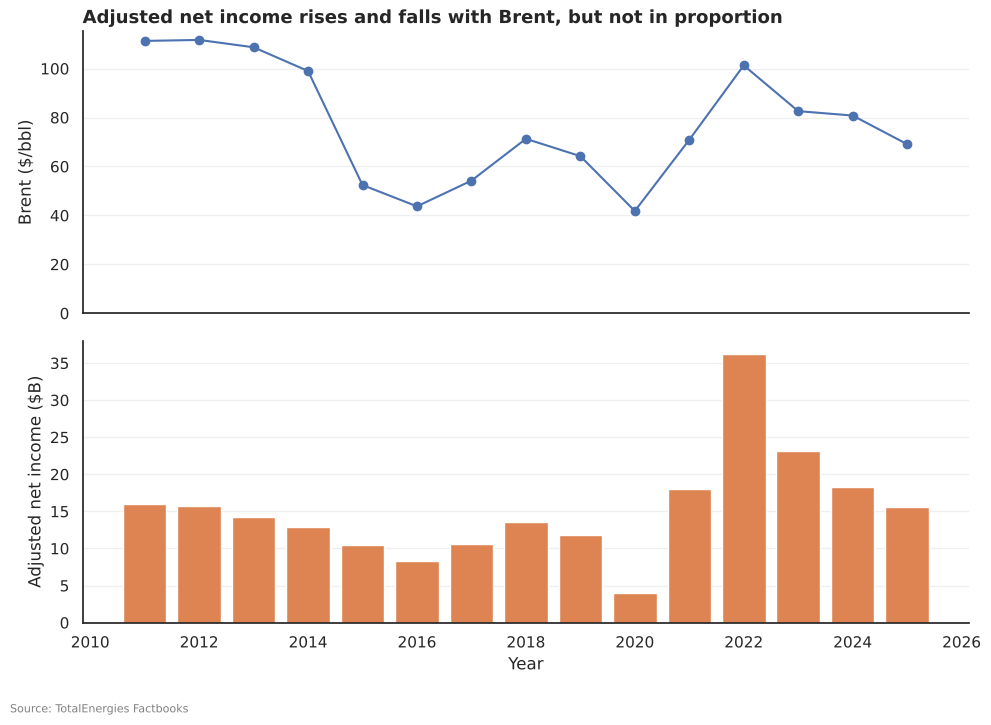

In [11]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

ax1.plot(annual["year"], annual["brent_avg_usd_per_bbl"], marker="o", color=BLUE)
ax1.set_ylim(bottom=0)
format_axes(ax1, "Adjusted net income rises and falls with Brent, but not in proportion",
            "", "Brent ($/bbl)", source=None)

ax2.bar(annual["year"], annual["adjusted_net_income_busd"], color=ORANGE)
format_axes(ax2, "", "Year", "Adjusted net income ($B)")

fig.tight_layout()
plt.show()

To compare all indicators on the same scale, I convert them to an index: each series is divided by its 2011 value and multiplied by 100.

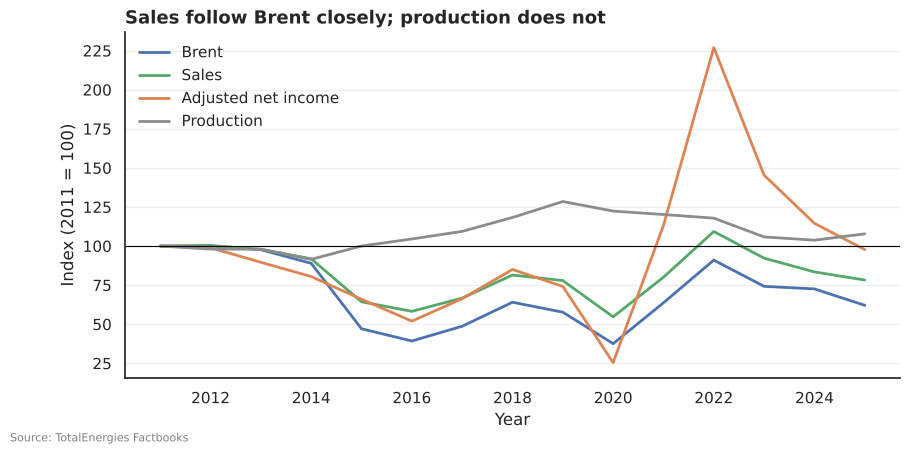

In [12]:
indicators = {
    "brent_avg_usd_per_bbl": "Brent",
    "sales_musd": "Sales",
    "adjusted_net_income_musd": "Adjusted net income",
    "production_kboe_per_day": "Production",
}
index_2011 = annual.set_index("year")[list(indicators)].rename(columns=indicators)
index_2011 = index_2011 / index_2011.iloc[0] * 100

fig, ax = plt.subplots()
index_2011.plot(ax=ax, color=[BLUE, GREEN, ORANGE, GREY], linewidth=2)
ax.axhline(100, color="black", linewidth=0.8)
format_axes(ax, "Sales follow Brent closely; production does not", "Year", "Index (2011 = 100)")
ax.legend(frameon=False)
plt.show()

**Interpretation.** Adjusted net income generally moves in the same direction as Brent. It fell from USD 15.9 billion in 2011 to USD 8.3 billion in 2016 as Brent dropped from 111 to 44 USD/bbl, collapsed to USD 4.1 billion in 2020, and peaked at USD 36.2 billion in 2022.

The relationship is not proportional, though. In 2011-2013, with Brent above 100 USD/bbl, adjusted net income stayed between USD 14 and 16 billion. In 2022, with a similar Brent price (101 USD/bbl), it reached more than twice that level. Brent is not the only driver: European gas prices, for example, averaged 40.5 USD/Mbtu in 2022, against 16 in 2021 and 13.1 in 2023 (TTF price, Factbook 2025).

The index chart shows the same contrast. Sales follow Brent closely, which is expected since they are mostly volumes multiplied by prices. Production, on the other hand, rose by 28% between 2011 and 2019 while Brent fell, which partly cushioned the effect of lower prices on sales.

### 2.2 Correlations

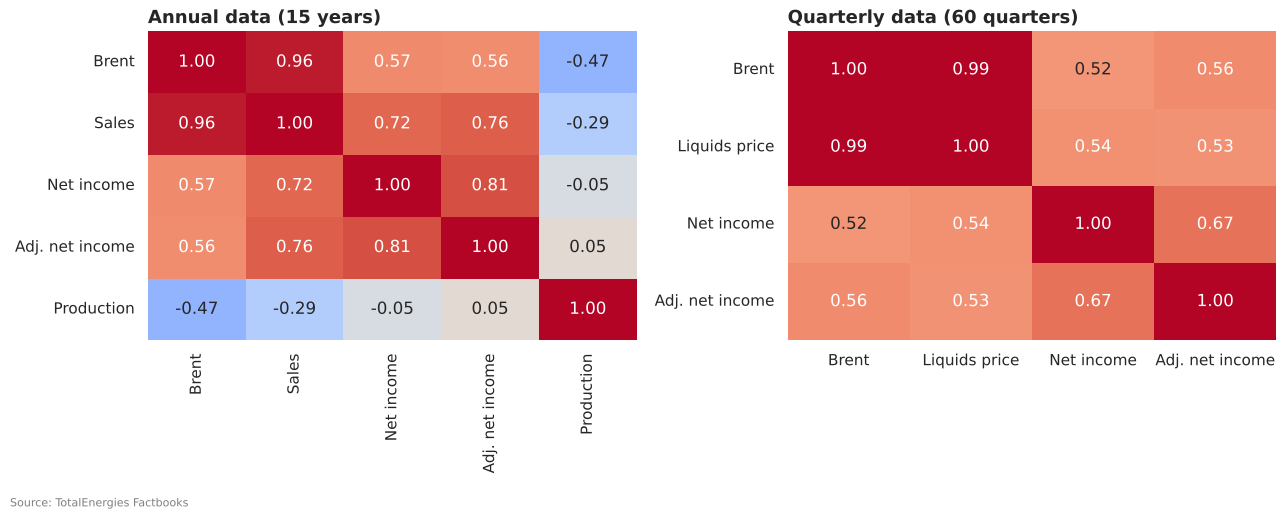

In [13]:
labels_annual = {
    "brent_avg_usd_per_bbl": "Brent",
    "sales_musd": "Sales",
    "net_income_musd": "Net income",
    "adjusted_net_income_musd": "Adj. net income",
    "production_kboe_per_day": "Production",
}
labels_quarterly = {
    "brent_avg_usd_per_bbl": "Brent",
    "avg_liquids_price_usd_per_bbl": "Liquids price",
    "net_income_musd": "Net income",
    "adjusted_net_income_musd": "Adj. net income",
}
corr_annual = annual[list(labels_annual)].rename(columns=labels_annual).corr()
corr_quarterly = quarterly[list(labels_quarterly)].rename(columns=labels_quarterly).corr()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, corr, title in [(axes[0], corr_annual, "Annual data (15 years)"),
                        (axes[1], corr_quarterly, "Quarterly data (60 quarters)")]:
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=False, ax=ax)
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.03, "Source: TotalEnergies Factbooks", fontsize=8, color="gray")
fig.tight_layout()
plt.show()

**Interpretation.** Brent is almost perfectly correlated with sales (0.96) and with the price TotalEnergies actually receives for its liquids (0.99 on quarterly data). Its correlation with adjusted net income is only moderate (0.56), on both annual and quarterly data: prices explain a large part of the variation in income, but far from all of it.

Production is negatively correlated with Brent (-0.47), because it rose during the 2015-2019 period of low prices. With only 15 years of data, a single unusual year such as 2022 weighs heavily on these coefficients, so they should be read as orders of magnitude.

## 3. How much is a higher oil price worth?

### 3.1 Estimating the sensitivity

The slope of the trend line of adjusted net income against Brent gives, on average, the extra income for each additional dollar of Brent. `np.polyfit(x, y, 1)` fits this line and returns its slope, then its intercept.

A quarterly slope covers one quarter, so I multiply it by 4 to compare it with an annual slope.

Effect of +$10/bbl on adjusted net income (annual data):    +1.70 $B per year
Effect of +$10/bbl on adjusted net income (quarterly data): +1.74 $B per year


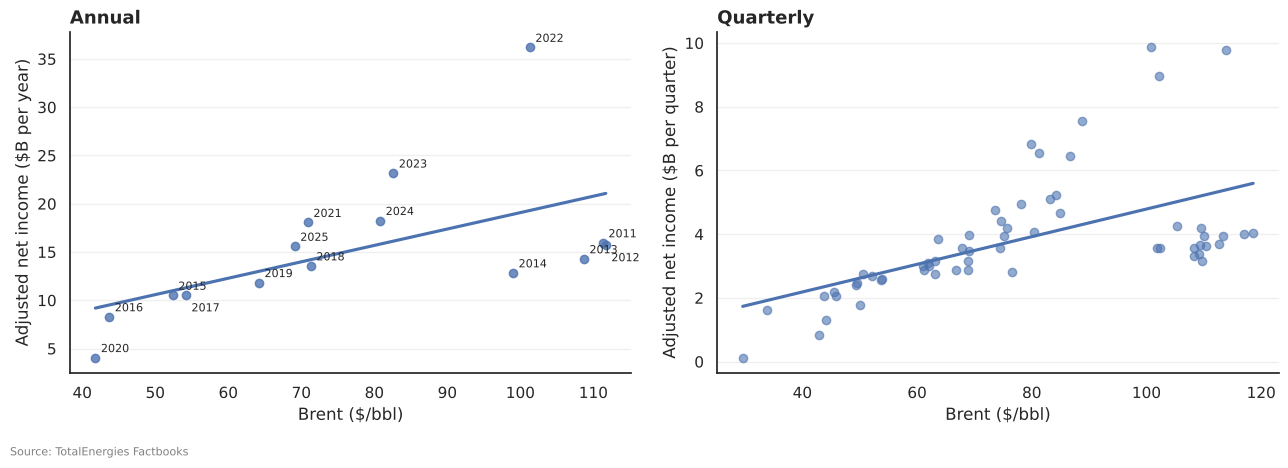

In [14]:
def slope(x: pd.Series, y: pd.Series) -> float:
    """Return the slope of the linear trend of y as a function of x."""
    return np.polyfit(x, y, 1)[0]


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.regplot(data=annual, x="brent_avg_usd_per_bbl", y="adjusted_net_income_busd", ci=None,
            color=BLUE, ax=axes[0])
label_offsets = {2012: (4, -12), 2017: (4, -12)}  # move two labels that would overlap their neighbours
for _, row in annual.iterrows():
    axes[0].annotate(int(row["year"]), (row["brent_avg_usd_per_bbl"], row["adjusted_net_income_busd"]),
                     xytext=label_offsets.get(int(row["year"]), (4, 4)), textcoords="offset points", fontsize=8)
format_axes(axes[0], "Annual", "Brent ($/bbl)", "Adjusted net income ($B per year)", source=None)

sns.regplot(data=quarterly, x="brent_avg_usd_per_bbl", y="adjusted_net_income_busd", ci=None,
            color=BLUE, scatter_kws={"alpha": 0.6}, ax=axes[1])
format_axes(axes[1], "Quarterly", "Brent ($/bbl)", "Adjusted net income ($B per quarter)")

fig.tight_layout()
plt.show()

effect_annual = slope(annual["brent_avg_usd_per_bbl"], annual["adjusted_net_income_musd"]) * 10 / 1000
effect_quarterly = slope(quarterly["brent_avg_usd_per_bbl"], quarterly["adjusted_net_income_musd"]) * 4 * 10 / 1000
print(f"Effect of +$10/bbl on adjusted net income (annual data):    {effect_annual:+.2f} $B per year")
print(f"Effect of +$10/bbl on adjusted net income (quarterly data): {effect_quarterly:+.2f} $B per year")

### 3.2 Comparison with the official sensitivity

For 2025, TotalEnergies estimates that a change of ±10 USD/bbl in the average price of its liquids changes its adjusted net operating income by about ±USD 2.3 billion (press release "Fourth Quarter 2025: Main Indicators"). The official figure differs from my first estimate in three ways: it uses the price of the liquids TotalEnergies actually sells (not Brent), adjusted net operating income (not net income), and the 2025 portfolio (not a 15-year average).

I redo the estimate to get closer to the official definition: first with the liquids price, then with adjusted net operating income (the sum of all segments). The annual liquids price is the average of the four quarters.

In [15]:
annual_liquids = quarterly.groupby("year")["avg_liquids_price_usd_per_bbl"].mean()
annual_anoi = segments.groupby("year")["adjusted_net_operating_income_musd"].sum()

estimates = pd.DataFrame([
    {"price": "Brent", "income": "Adjusted net income", "data": "Annual, 2011-2025",
     "effect_of_+10_usd_busd": effect_annual},
    {"price": "Brent", "income": "Adjusted net income", "data": "Quarterly, 2011-2025",
     "effect_of_+10_usd_busd": effect_quarterly},
    {"price": "Liquids", "income": "Adjusted net income", "data": "Quarterly, 2011-2025",
     "effect_of_+10_usd_busd": slope(quarterly["avg_liquids_price_usd_per_bbl"],
                                     quarterly["adjusted_net_income_musd"]) * 4 * 10 / 1000},
    {"price": "Liquids", "income": "Adjusted net operating income", "data": "Annual, 2011-2025",
     "effect_of_+10_usd_busd": slope(annual_liquids, annual_anoi) * 10 / 1000},
    {"price": "Liquids", "income": "Adjusted net operating income", "data": "Official sensitivity, 2025 portfolio",
     "effect_of_+10_usd_busd": 2.3},
])
estimates.round(2)

,price,income,data,effect_of_+10_usd_busd
0,Brent,Adjusted net income,"Annual, 2011-2025",1.70
1,Brent,Adjusted net income,"Quarterly, 2011-2025",1.74
2,Liquids,Adjusted net income,"Quarterly, 2011-2025",1.69
3,Liquids,Adjusted net operating income,"Annual, 2011-2025",1.64
4,Liquids,Adjusted net operating income,"Official sensitivity, 2025 portfolio",2.30


**Interpretation.** All four estimates are close: about USD 1.6 to 1.7 billion per year for a 10 USD/bbl increase, whether I use Brent or the liquids price, net income or operating income, annual or quarterly data. They are clearly below the official sensitivity of USD 2.3 billion. Three reasons can explain the gap:

- **Portfolio:** the official figure applies to the 2025 portfolio. Production was 2,529 kboe/d in 2025, against 2,146 to 2,452 kboe/d in 2011-2016: more barrels means a larger effect per dollar.
- **Method:** the official sensitivity isolates the effect of the price, all else being equal. My regression measures a historical average, which also includes everything that moved at the same time as oil prices (costs, taxes, refining margins, gas prices).
- **Data:** 15 points is little, and the regression is sensitive to outliers such as 2011-2014 (well below the line) and 2022 (well above).

My estimate therefore measures the historical link between Brent and results, not the pure effect of the price.